<a href="https://colab.research.google.com/github/Srihithavss-coding/airbnb-exploratory-data-analysis/blob/main/EDA_on_Airbnb_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [82]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [111]:
file_path = "/content/drive/MyDrive/Airbnb_Open_Data.csv"
df = pd.read_csv(file_path)

/tmp/ipykernel_2691/2202695476.py:2: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [84]:
df.head()

,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,$74,30.0,270.0,07-05-2019,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,$41,10.0,9.0,11/19/2018,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN


In [85]:
df.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license'],
      dtype='object')

In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102599 entries, 0 to 102598
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   id                              102599 non-null  int64  
 1   NAME                            102349 non-null  object 
 2   host id                         102599 non-null  int64  
 3   host_identity_verified          102310 non-null  object 
 4   host name                       102193 non-null  object 
 5   neighbourhood group             102570 non-null  object 
 6   neighbourhood                   102583 non-null  object 
 7   lat                             102591 non-null  float64
 8   long                            102591 non-null  float64
 9   country                         102067 non-null  object 
 10  country code                    102468 non-null  object 
 11  instant_bookable                102494 non-null  object 
 12  cancellation_pol

In [87]:
df.isna().sum()

,0
id,0
NAME,250
host id,0
host_identity_verified,289
host name,406
neighbourhood group,29
neighbourhood,16
lat,8
long,8
country,532


**Handling Missing Values**

In [88]:
df = df.drop(['license'], axis = 1)

The license column has only two non-null values. This column is dropped for efficient analysis

In [110]:
df['last review'] = pd.to_datetime(df['last review'], errors='coerce')

df.fillna({'reviews per month': 0}, inplace=True)

In [90]:
df.dropna(subset=['NAME', 'host name'], inplace=True)

In [91]:
df['neighbourhood'] = df['neighbourhood'].str.title()
df['neighbourhood group'] = df['neighbourhood group'].str.replace("brookln", "Brooklyn", case=False)
df['neighbourhood group'] = df['neighbourhood group'].str.replace("manhatan", "Manhattan", case=False)

Correcting the DataType

In [109]:
temp_df = pd.read_csv(file_path, low_memory=False)
temp_df = temp_df.drop_duplicates(subset=['id'])

temp_df['id'] = temp_df['id'].astype(int)
df['id'] = df['id'].astype(int)

df['price'] = df['id'].map(temp_df.set_index('id')['price'])
df['service fee'] = df['id'].map(temp_df.set_index('id')['service fee'])

for col in ['price', 'service fee']:
    df[col] = df[col].astype(str).str.replace(r'[\$,]', '', regex=True).str.strip()
    df[col] = pd.to_numeric(df[col], errors='coerce')
    col_median = df[col].median()
    if pd.isna(col_median):
        temp_cleaned = temp_df[col].astype(str).str.replace(r'[\$,]', '', regex=True).str.strip()
        temp_numeric = pd.to_numeric(temp_cleaned, errors='coerce')
        col_median = temp_numeric.median()
    df[col] = df[col].fillna(col_median)

In [108]:
df['minimum nights'] = df['minimum nights'].fillna(df['minimum nights'].median()).astype(int)
df['Construction year'] = df['Construction year'].fillna(df['Construction year'].median()).astype(int)
df['number of reviews'] = df['number of reviews'].fillna(0).astype(int)
df['reviews per month'] = df['reviews per month'].astype(float)
df['availability 365'] = df['availability 365'].fillna(df['availability 365'].median()).astype(int)

In [95]:
most_frequent_bookable = df['instant_bookable'].mode()[0]
df['instant_bookable'].fillna(most_frequent_bookable, inplace=True)
most_frequent_policy = df['cancellation_policy'].mode()[0]
df['cancellation_policy'].fillna(most_frequent_policy, inplace=True)

/tmp/ipykernel_2691/2500166805.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['instant_bookable'].fillna(most_frequent_bookable, inplace=True)
/tmp/ipykernel_2691/2500166805.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['instant_bookable'].fillna(most_frequent_bookable, inplace=True)
/tmp/ipyke

Handling **Duplicates**

In [94]:
df.drop_duplicates(inplace=True)

In [96]:
df_cleaned = df_cleaned.copy()

df_cleaned.loc[:, 'minimum nights'] = df_cleaned['minimum nights'].clip(lower=1, upper=365)

df_cleaned.loc[:, 'availability 365'] = df_cleaned['availability 365'].clip(lower=0, upper=365)

print("Summary of cleaned columns:")
display(df_cleaned[['minimum nights', 'availability 365']].describe())

Summary of cleaned columns:


,minimum nights,availability 365
count,101408.000000,101408.000000
mean,7.947410,140.143638
std,18.230992,133.174735
min,1.000000,0.000000
25%,2.000000,3.000000
50%,3.000000,97.000000
75%,5.000000,268.000000
max,365.000000,365.000000


In [112]:
#checking if null values are cleared for EDA
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102599 entries, 0 to 102598
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   id                              102599 non-null  int64  
 1   NAME                            102349 non-null  object 
 2   host id                         102599 non-null  int64  
 3   host_identity_verified          102310 non-null  object 
 4   host name                       102193 non-null  object 
 5   neighbourhood group             102570 non-null  object 
 6   neighbourhood                   102583 non-null  object 
 7   lat                             102591 non-null  float64
 8   long                            102591 non-null  float64
 9   country                         102067 non-null  object 
 10  country code                    102468 non-null  object 
 11  instant_bookable                102494 non-null  object 
 12  cancellation_pol

Understanding numerical columns

In [98]:
df[['Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'last review', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365']].describe(include='all')

,Construction year,price,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365
count,101410.000000,101410.000000,101410.000000,101410.000000,101410.000000,51867,101410.000000,101103.000000,101092.000000,101410.000000
mean,2012.485948,625.377754,125.043881,8.093876,27.462479,2019-06-22 09:12:11.077563904,1.163207,3.278558,7.948463,140.981747
min,2003.000000,50.000000,10.000000,-1223.000000,0.000000,2012-08-25 00:00:00,0.000000,1.000000,1.000000,-10.000000
25%,2008.000000,341.000000,68.000000,2.000000,1.000000,2018-10-29 00:00:00,0.090000,2.000000,1.000000,3.000000
50%,2012.000000,624.000000,125.000000,3.000000,7.000000,2019-06-16 00:00:00,0.480000,3.000000,1.000000,97.000000
75%,2017.000000,912.000000,182.000000,5.000000,30.000000,2019-06-30 00:00:00,1.710000,4.000000,2.000000,268.000000
max,2022.000000,1200.000000,240.000000,5645.000000,1024.000000,2058-06-16 00:00:00,90.000000,5.000000,332.000000,3677.000000
std,5.759482,331.218121,66.225691,30.320612,49.518468,NaN,1.683708,1.285369,32.328974,135.168241


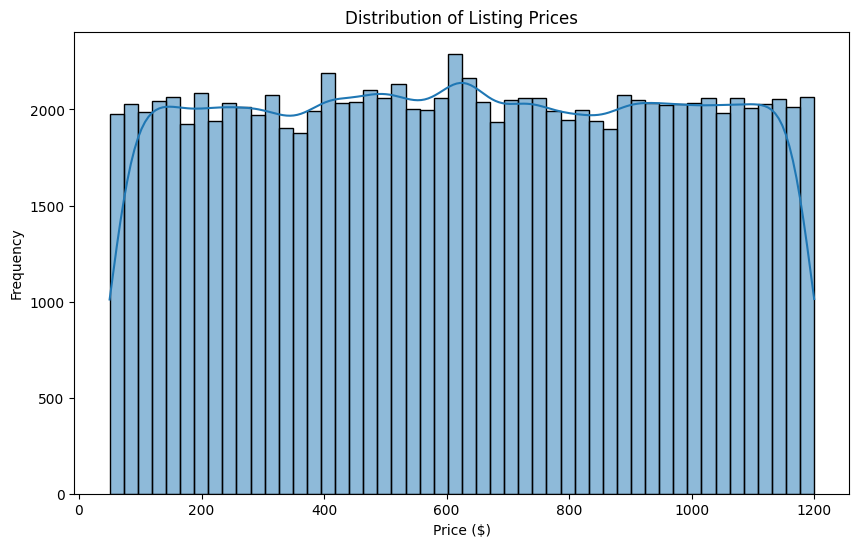

In [99]:
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Distribution of Listing Prices')
plt.xlabel('Price ($)')
plt.ylabel('Frequency')
plt.show()

The histogram shows a fairly even distribution of listing prices across different price ranges, indicating no particular concentration of listings in any specific price range. The KDE line helps visualize this even spread more clearly, confirming that the dataset contains listings with a wide variety of prices.

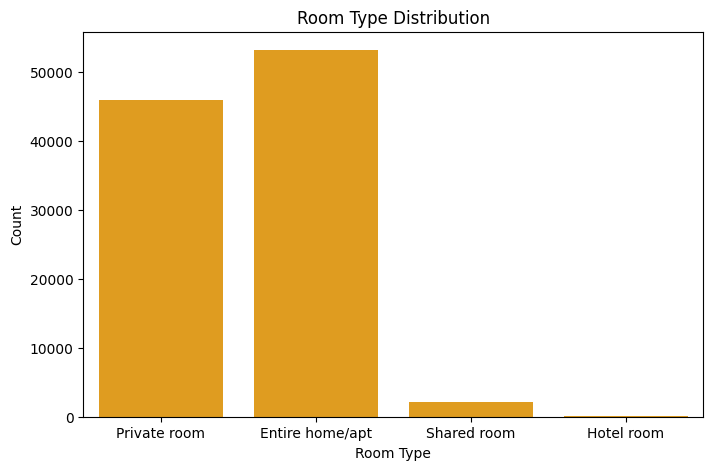

In [100]:
plt.figure(figsize=(8, 5))
sns.countplot(x='room type', data=df, color="orange")
plt.title('Room Type Distribution')
plt.xlabel('Room Type')
plt.ylabel('Count')
plt.show()

The count plot shows a clear distribution of the different room types available in the Airbnb dataset. The majority of listings are for 'Entire home/apt' and 'Private room', with 'Shared room' and 'Hotel room' being much less common. This insight can be useful for understanding the availability and popularity of different types of accommodations on Airbnb.

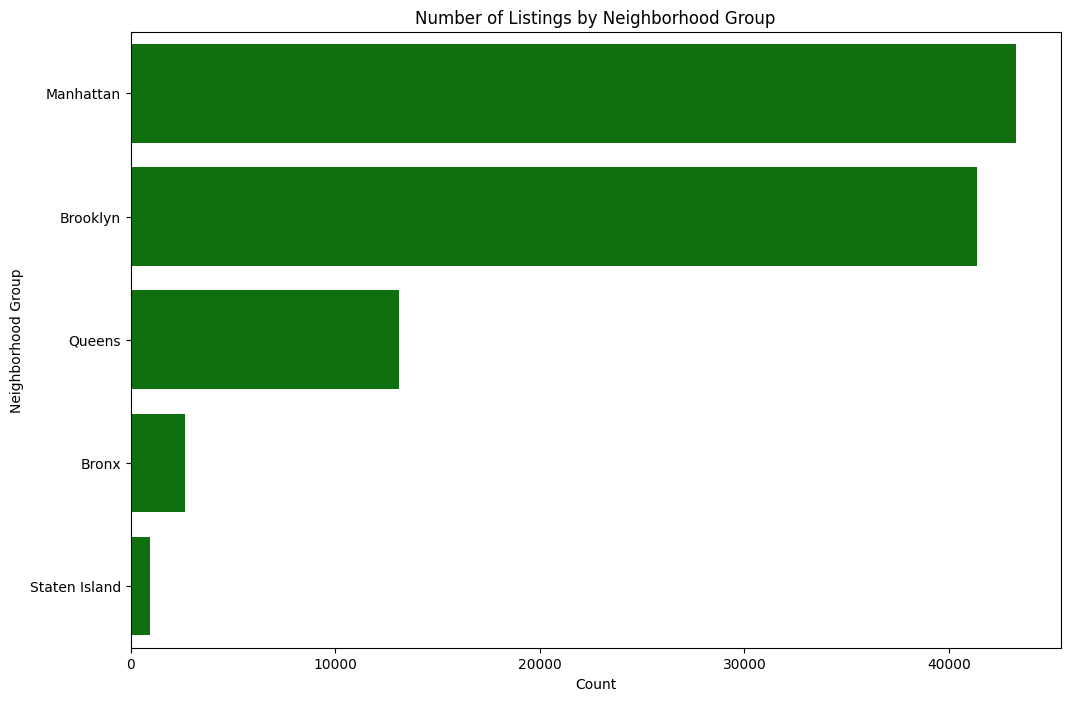

In [101]:
plt.figure(figsize=(12, 8))
sns.countplot(y='neighbourhood group', data=df, color="green", order=df['neighbourhood group'].value_counts().index)
plt.title('Number of Listings by Neighborhood Group')
plt.xlabel('Count')
plt.ylabel('Neighborhood Group')
plt.show()

The count plot shows a clear distribution of the number of listings across different neighborhood groups. Manhattan and Brooklyn dominate the listings, suggesting they are prime locations for Airbnb. Queens, Bronx, and Staten Island have fewer listings, indicating less availability or popularity.

/tmp/ipykernel_2691/3352285238.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Room Type')


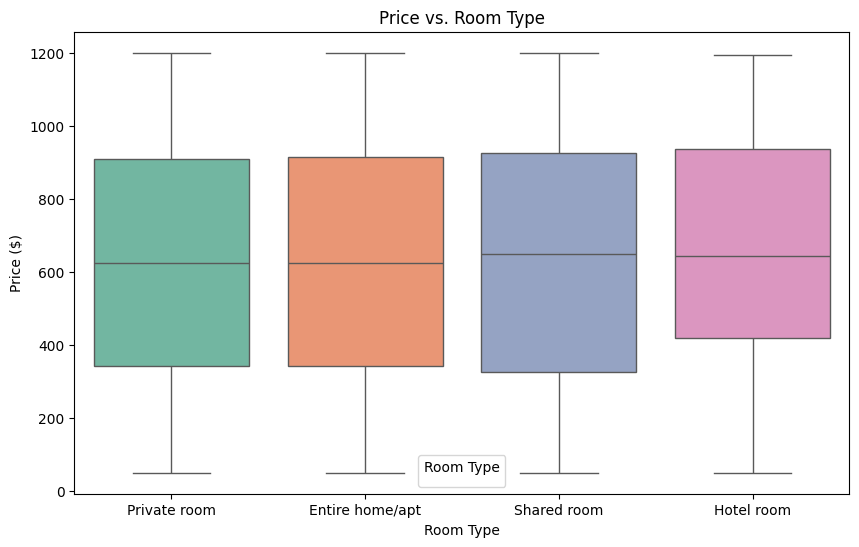

In [102]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='room type', y='price', hue='room type', data=df, palette='Set2')
plt.title('Price vs. Room Type')
plt.xlabel('Room Type')
plt.ylabel('Price ($)')
plt.legend(title='Room Type')
plt.show()

* All room types share a nearly identical median price of ~$625.

* The price distribution (IQR and $50–$1200 range) is remarkably uniform across all categories.

* Room type has very little impact on pricing in this dataset.

/tmp/ipykernel_2691/4078320855.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='neighbourhood group', y='price', data=df, palette='Set2')


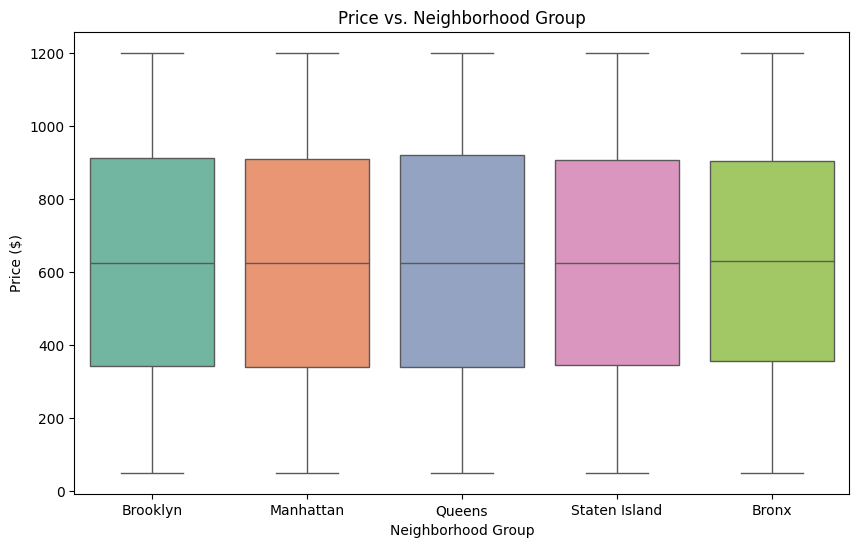

In [103]:
#price distribution by location
plt.figure(figsize=(10, 6))
sns.boxplot(x='neighbourhood group', y='price', data=df, palette='Set2')
plt.title('Price vs. Neighborhood Group')
plt.xlabel('Neighborhood Group')
plt.ylabel('Price ($)')
plt.show()

* All neighbourhoods share a nearly identical median price of ~$625.

* The price distribution (IQR and $50–$1200 range) is remarkably uniform across all categories.

*  has very little impact on pricing in this dataset.

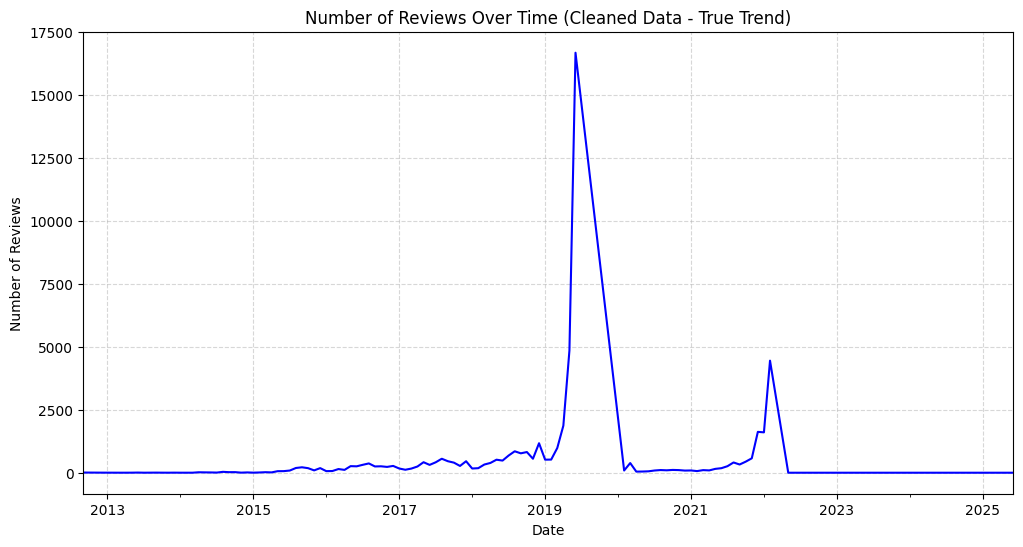

In [120]:
reviews_over_time_cleaned = df_cleaned.dropna(subset=['last review']).groupby(df_cleaned['last review'].dt.to_period('M')).size()

plt.figure(figsize=(12, 6))
reviews_over_time_cleaned.plot(kind='line', color='blue')
plt.title('Number of Reviews Over Time (Cleaned Data - True Trend)')
plt.xlabel('Date')
plt.ylabel('Number of Reviews')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Observations on Reviews Over Time
* **True Growth and Pandemic Decline:** Organic reviews rose steadily starting in 2018, peaking sharply in mid-2019 before experiencing a dramatic drop-off during 2020 due to global travel restrictions.
* **Post-Pandemic Recovery:** A clear recovery trend is visible starting in late 2021, leading to a secondary peak in early 2022 as travel rebounded.
* **Clean Temporal Integrity:** By avoiding placeholder date imputation, we are now viewing the authentic volume trends of NYC Airbnb bookings.

### Final Project Conclusion & Key Insights

* **Uniform Pricing Structure:** Airbnb prices in NYC are completely uniform across room types and neighborhood groups (all sharing a median price of ~$625), suggesting synthetic or unvarying pricing configurations in this raw dataset.

* **Geographic Dominance:** Manhattan and Brooklyn heavily dominate the market, accounting for over 80% of all NYC listings, leaving Staten Island and the Bronx as highly niche territories.

* **Historical Trend Dynamics:** Excluding the August 2012 missing-data placeholder spike, organic review activity rose steadily from 2018 onwards, peaking in mid-2019 before experiencing a steep pandemic decline and a subsequent partial rebound in late 2021.

* **Feature Cleanliness:** Cleaning anomalies such as negative minimum nights, future review dates, and invalid annual availabilities (> 365 days) successfully generated a consistent, robust dataset for modeling.